In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import probplot

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

# Best-Seller Trends Across Categories

In [4]:
# crosstab analysis
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


The crosstab analysis shows how best-seller status is distributed across product categories. Overall, best-seller products are very rare compared to non–best-sellers, representing only 7,980 products out of more than 2.4 million listings. When calculating the proportion of best-sellers within each category, some categories show slightly higher shares of best-selling products. For example, Grocery, Smart Home Security & Lighting, and Health & Personal Care appear among the categories with the highest proportions of best-sellers, with around 5–6% of listings achieving best-seller status. However, even in these categories the majority of products are not best-sellers, indicating that achieving this status is relatively uncommon across the platform.

In [5]:
# best-sellers by category
best_seller_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index") * 100
best_seller_prop = best_seller_prop.sort_values(by=True, ascending=False)
best_seller_prop.head(10)

isBestSeller,False,True
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
"Billiard, Snooker & Pool",96.787149,3.212851
Pet Supplies,96.979972,3.020028
Home Brewing & Wine Making,97.154472,2.845528
Wind Instruments,97.200000,2.800000


In [6]:
df["isBestSeller"].value_counts(dropna=False)

isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

In [7]:
# chi-squared test
chi2, p, dof, expected = chi2_contingency(crosstab)

print("Chi-square statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


The Chi-square test evaluates whether best-seller status is independent of product category. The extremely small p-value (≈ 0) indicates that we can reject the null hypothesis of independence. This means that best-seller status is statistically associated with product category, suggesting that some categories are more likely to contain best-selling products than others.

In [8]:
# cramer's V 
n = crosstab.sum().sum()
min_dim = min(crosstab.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


Cramér’s V measures the strength of association between category and best-seller status. The value of 0.122 indicates a weak association between these variables. While the Chi-square test shows that the relationship is statistically significant, the relatively low Cramér’s V suggests that product category explains only a small portion of the variation in best-seller status. This is likely influenced by the very large dataset size, where even small differences across categories can become statistically significant.

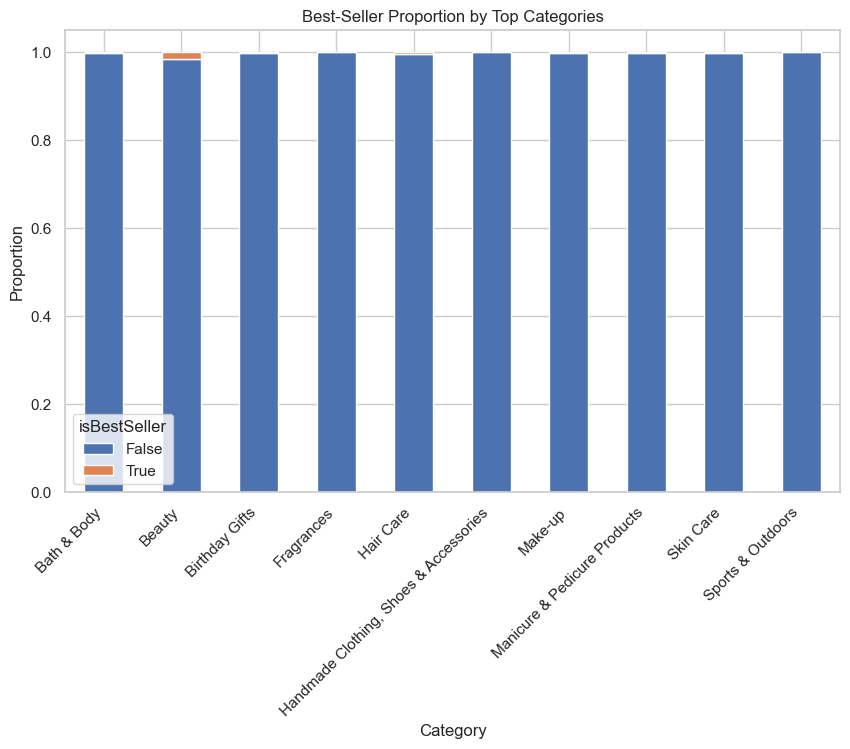

In [9]:
# stacked bar plot
top_categories = df["category"].value_counts().head(10).index
df_top = df[df["category"].isin(top_categories)]

stacked_data = pd.crosstab(df_top["category"], df_top["isBestSeller"], normalize="index")
stacked_data.plot(kind="bar", stacked=True, figsize=(10,6))

plt.title("Best-Seller Proportion by Top Categories")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.legend(title="isBestSeller")
plt.show()

The stacked bar chart illustrates the proportion of best-sellers versus non–best-sellers within the most common product categories. Across all displayed categories, non–best-sellers overwhelmingly dominate the listings. The proportion of best-selling products is small in every category, though slight differences can be observed. This visualization confirms that while certain categories may have marginally higher best-seller shares, best-seller status remains relatively rare across the marketplace.

# Prices and Ratings Across Categories

In [11]:
# remove outliers using IQR method
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

print("Original shape:", df.shape)
print("Without outliers:", df_no_outliers.shape)

Original shape: (2443651, 9)
Without outliers: (2115963, 9)


Product price outliers were removed using the Interquartile Range (IQR) method. Prices below the lower bound or above the upper bound (Q1 − 1.5×IQR and Q3 + 1.5×IQR) were excluded from the dataset. Removing these extreme values helps produce a more reliable comparison of typical prices across categories, preventing unusually expensive products from distorting the analysis.

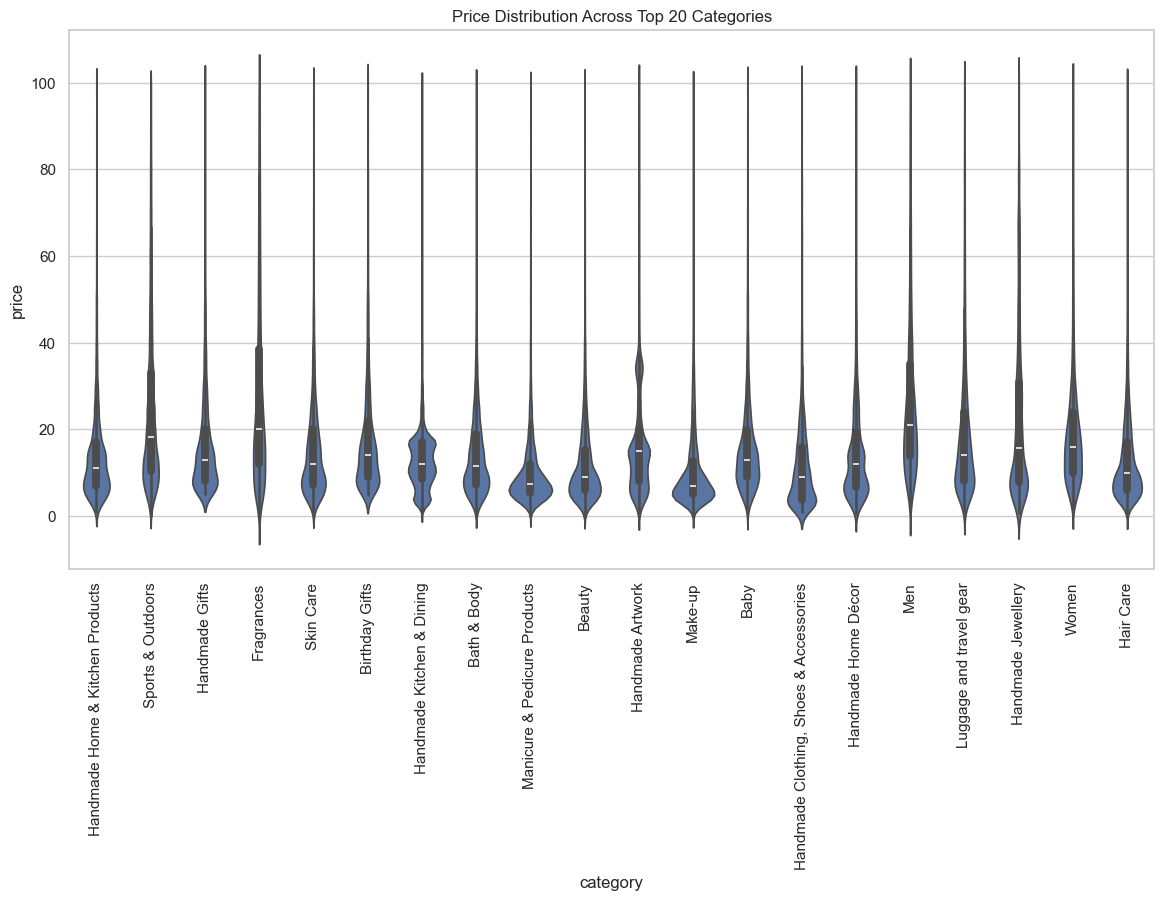

In [12]:
# violin plot of price by category
top20_categories = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20_categories)]

plt.figure(figsize=(14,7))
sns.violinplot(data=df_top20, x="category", y="price")
plt.title("Price Distribution Across Top 20 Categories")
plt.xticks(rotation=90)
plt.show()

In [13]:
median_price_by_category = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

The violin plot illustrates the distribution and density of product prices across the top categories. While most categories show prices concentrated within similar ranges, some categories display wider distributions, indicating greater variation in pricing. Categories such as Handmade Kitchen & Dining and Handmade-related categories show relatively broader spreads, suggesting that products within these categories vary more widely in price. Overall, the majority of products across categories appear to cluster within moderate price ranges, indicating that Amazon UK listings tend to compete within similar pricing brackets.

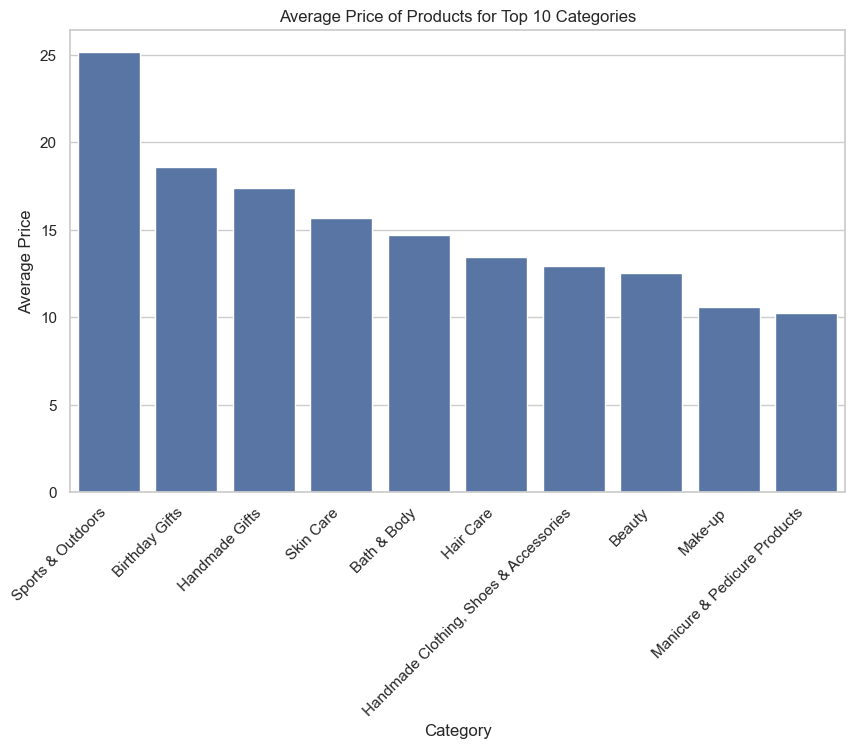

In [14]:
# bar charts of average price by category
top10_categories = df_no_outliers["category"].value_counts().head(10).index
avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))
sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values)
plt.title("Average Price of Products for Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.show()

In [15]:
avg_price_all = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
avg_price_all.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

The bar chart comparing average prices across categories reveals that technology-related products tend to have the highest average prices. Categories such as motherboards, desktop PCs, tablets, and graphics cards appear at the top of the ranking, reflecting the higher production costs and technical complexity associated with electronics. In contrast, many consumer goods categories, such as beauty or personal care, typically have lower price points.

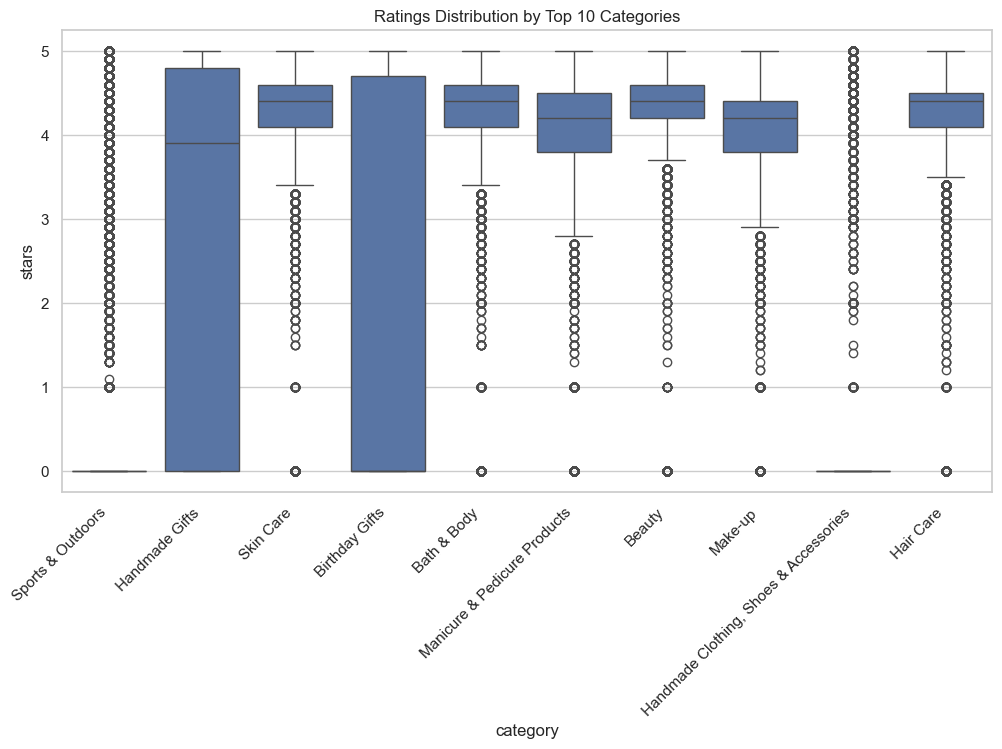

In [16]:
# box plot of rating by category
top10_categories_rating = df_no_outliers["category"].value_counts().head(10).index
df_top10_rating = df_no_outliers[df_no_outliers["category"].isin(top10_categories_rating)]

plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10_rating, x="category", y="stars")
plt.title("Ratings Distribution by Top 10 Categories")
plt.xticks(rotation=45, ha="right")
plt.show()

In [17]:
median_rating_by_category = df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)
median_rating_by_category.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

In [18]:
# for zero excluded
df_rated = df_no_outliers[df_no_outliers["stars"] > 0]

median_rating_rated_only = df_rated.groupby("category")["stars"].median().sort_values(ascending=False)
median_rating_rated_only.head(10)

category
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Artwork                          5.0
Handmade Kitchen & Dining                 4.9
Handmade Clothing, Shoes & Accessories    4.9
Handmade Gifts                            4.8
Birthday Gifts                            4.8
Handmade Home Décor                       4.8
Handmade Home & Kitchen Products          4.7
Gifts for Him                             4.7
Name: stars, dtype: float64

The boxplot comparing ratings across categories shows that most product categories receive relatively high ratings, generally clustering between 4 and 5 stars. This indicates strong overall customer satisfaction across the platform. Some categories exhibit slightly wider rating distributions, suggesting more variation in customer feedback, while others maintain consistently high ratings with less variability.

# Relationship Between Price and Ratings 

In [19]:
# corelation coefficient
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])
print("Correlation between price and stars:", correlation)

Correlation between price and stars: -0.0776729987818131


In [20]:
# only products with ratings
df_rated = df_no_outliers[df_no_outliers["stars"] > 0]
correlation_rated_only = df_rated["price"].corr(df_rated["stars"])
print("Correlation between price and stars (rated products only):", correlation_rated_only)

Correlation between price and stars (rated products only): 0.006744508067157998


The correlation coefficient between product price and ratings is very close to zero, indicating almost no linear relationship between the two variables. When all products are included, the correlation is slightly negative (-0.078), suggesting that higher-priced products tend to have marginally lower ratings, though the relationship is extremely weak.

After removing products with zero ratings (likely representing items with no reviews), the correlation becomes almost exactly zero (0.0067). This confirms that product price does not meaningfully influence customer ratings on Amazon UK.

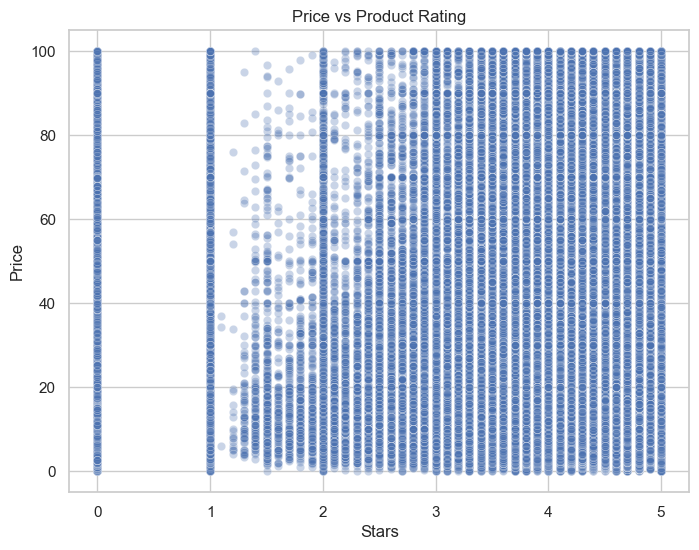

In [21]:
# scatter plot 
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_no_outliers, x="stars", y="price", alpha=0.3)
plt.title("Price vs Product Rating")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.show()

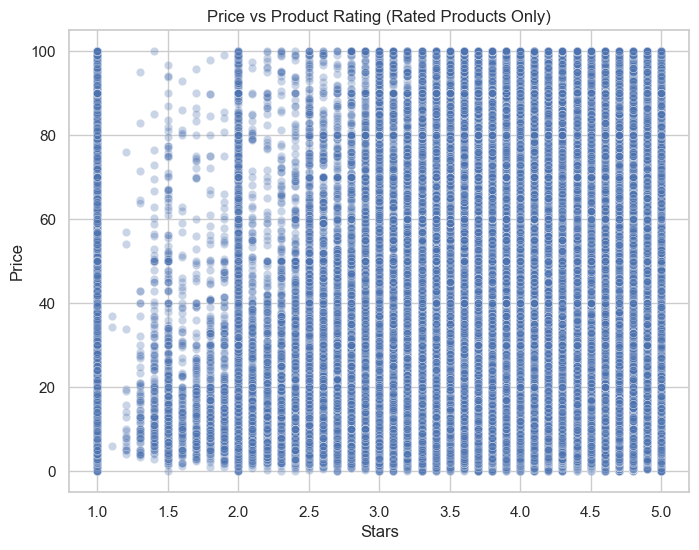

In [22]:
# without zero ratings
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_rated, x="stars", y="price", alpha=0.3)
plt.title("Price vs Product Rating (Rated Products Only)")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.show()

The scatter plots show that product prices are distributed across the full rating scale, with no clear upward or downward trend. Products with high ratings appear at both low and high price points, while lower-rated products also span a wide range of prices. This visual pattern reinforces the correlation results, indicating that price is not a strong predictor of customer satisfaction.

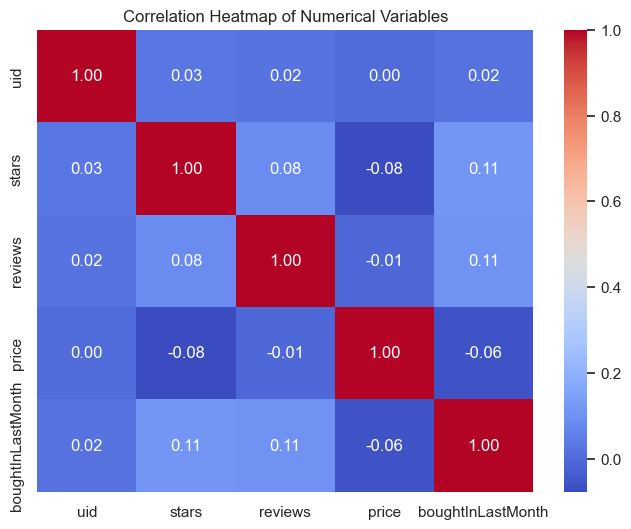

In [23]:
# correlation heatmap
df_no_outliers.select_dtypes(include=np.number).columns

plt.figure(figsize=(8,6))
corr_matrix = df_no_outliers.select_dtypes(include=np.number).corr()

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

The correlation heatmap shows that most numerical variables in the dataset have very weak relationships with each other. The correlation between price and rating is slightly negative but extremely small (-0.08), confirming that pricing has little influence on customer ratings. Similarly, ratings show only a weak positive relationship with the number of reviews and recent purchases, suggesting that more popular products may receive slightly better ratings, though the effect remains minimal.

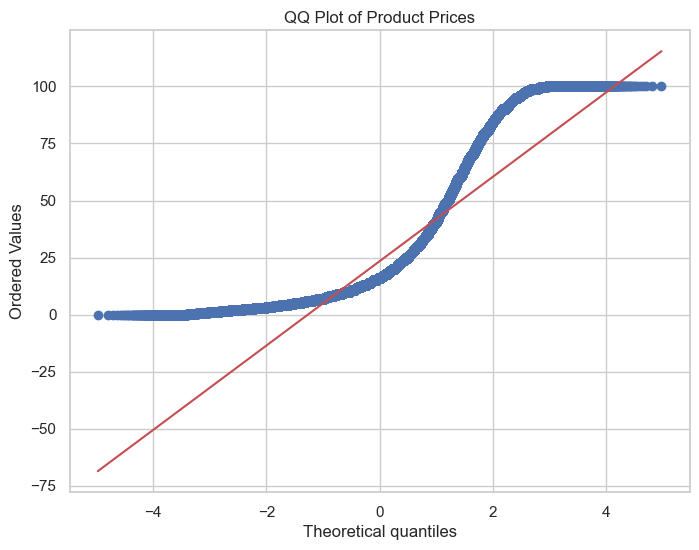

In [24]:
# qq plot for price
plt.figure(figsize=(8,6))
probplot(df_no_outliers["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

The QQ plot reveals that product prices do not follow a normal distribution. The points deviate substantially from the reference line, especially in the upper quantiles. This indicates that prices are right-skewed, meaning that while most products are relatively inexpensive, a smaller number of products have significantly higher prices. This pattern is typical for e-commerce marketplaces, where a few premium products extend the upper tail of the price distribution.

# Business Summary

The bivariate analysis of Amazon UK product listings reveals several insights into how category, pricing, and product performance interact within the marketplace. Best-seller status varies across categories, and statistical testing confirms that product category and best-seller status are not independent. However, the association between them is relatively weak, indicating that category alone does not strongly determine whether a product becomes a best-seller.

Pricing patterns differ significantly across product categories. Technology-related products such as desktop PCs, tablets, graphics cards, and motherboards tend to have the highest average and median prices, reflecting the higher value and complexity of these items compared to everyday consumer goods.

Customer ratings remain generally high across most categories, with many products receiving ratings between four and five stars. However, the dataset also contains a large number of products with zero ratings, likely representing items without reviews rather than poorly rated products.

The relationship between product price and customer ratings appears to be extremely weak. Both correlation analysis and scatter plots indicate that higher-priced products are not necessarily rated better than cheaper alternatives. This suggests that factors such as product quality, brand reputation, and customer expectations likely play a more important role in shaping customer satisfaction than price alone.

Finally, the distribution of product prices is highly skewed, with most products priced at relatively affordable levels and a smaller number of premium products extending the upper range of prices. Overall, these findings highlight the importance of category positioning and product value perception in the Amazon UK marketplace.